# 07 · Turning confidence into a flag

## How many clips must a reviewer read to catch the negative ones?

A predicted emotion with a confidence attached can drive a simple
triage rule: flag a clip for human review when the model predicts a
negative emotion and is confident about it. This notebook sweeps that
rule on the saved speaker-grouped predictions of every rung and asks
which rung catches more of the truly negative clips for the same
reviewing effort.

**Inherits:** `pred_confidence` and predictions from
`Modelling/outputs/preds/`, and the confidence result of
`06_Ladder_on_development_speakers`.
**Data:** the 1,080 development clips (the test speakers stay closed).
**Runtime:** about 10 s; nothing is trained here.
**Writes:** `outputs/tables/` (threshold sweep per rung, review-queue
sample) and figure F14.

**[ASSUMPTION]** The negative emotions are angry, fearful, sad and
disgust, and "negative" is judged at the level of this group: a clip
labelled angry and predicted sad counts as caught. Neither the list nor
the rule comes from the project brief; both are a sketch for the report.

In [1]:
# Setup: shared helpers, paths, and the rungs compared in this notebook.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib', 'inline')
import numpy as np
import pandas as pd
from IPython.display import display

HERE = Path.cwd()
SHARED = next(p / "shared" for p in [HERE, *HERE.parents]
              if (p / "shared" / "audio_utils.py").exists())
sys.path.insert(0, str(SHARED))

import audio_utils as U
import speaker_split as S

SUB = U.submission_root()
PREDS = SUB / "Modelling" / "outputs" / "preds"
OUT = SUB / "Evaluation" / "outputs"
TABLES, FIGS = OUT / "tables", OUT / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)

ALL_MODELS = ["logreg", "svc", "rf", "gbm", "cnn",
              "wav2vec2", "hubert", "wavlm", "fusion"]
RUNGS = ["logreg", "cnn", "wavlm"]
RUNG_LABEL = {"logreg": "Classical logreg", "cnn": "Log-mel CNN",
              "wavlm": "Frozen WavLM"}
RUNG_COLOR = {"logreg": U.MUTED, "cnn": U.GREY, "wavlm": U.ACCENT}
# [ASSUMPTION] see the opening cell.
NEGATIVE = ["angry", "fearful", "sad", "disgust"]

SUMMARY = []


def record(h, claim, verdict, evidence, decision):
    """Store one hypothesis result and print its verdict."""
    SUMMARY.append({
        "H": h, "hypothesis": claim, "verdict": verdict,
        "evidence": evidence, "so we": decision,
    })
    print(f"\n{h} · {claim}\n    verdict: {verdict.upper()}")


index = U.load_index()
dev = S.dev_mask(index)
S.assert_no_test_speakers(index.loc[dev, "filepath"], "dev mask")
print(f"dev clips: {int(dev.sum())}  test held out: {int((~dev).sum())}")


dev clips: 1080  test held out: 360


## 1 · The flag rule and its sweep

For a threshold t, a clip is **flagged** when the predicted emotion is
negative and its confidence is at least t. Three quantities describe a
threshold, all over the 1,080 development clips:

- **flag rate**: share of all clips flagged (the reviewing effort);
- **capture**: share of the truly negative clips that are flagged;
- **precision**: share of the flagged clips that are truly negative.

In [2]:
# Load the grouped-fold predictions of every rung and sweep the rule.
def load_preds(model: str) -> pd.DataFrame:
    """Stack the six speaker-grouped fold files of one model."""
    frames = []
    for k in range(6):
        path = PREDS / f"{model}_grouped_fold{k}.csv"
        df = pd.read_csv(path)
        S.assert_no_test_speakers(df["filepath"], path.name)
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


def sweep(df: pd.DataFrame, grid) -> pd.DataFrame:
    """Flag rate, capture and precision for each threshold.

    Parameters
    ----------
    df : pandas.DataFrame
        Predictions with ``true_emotion``, ``pred_emotion`` and
        ``pred_confidence``.
    grid : array-like of float
        Confidence thresholds (0-1).

    Returns
    -------
    pandas.DataFrame
        One row per threshold; flag rate, capture and precision are
        fractions (0-1).
    """
    true_neg = df["true_emotion"].isin(NEGATIVE).to_numpy()
    pred_neg = df["pred_emotion"].isin(NEGATIVE).to_numpy()
    conf = df["pred_confidence"].to_numpy()
    rows = []
    for t in grid:
        flagged = pred_neg & (conf >= t)
        n, caught = int(flagged.sum()), int((flagged & true_neg).sum())
        rows.append({
            "threshold": t, "n_flagged": n,
            "flag_rate": n / len(df),
            "capture": caught / true_neg.sum(),
            "precision": caught / n if n else np.nan,
        })
    return pd.DataFrame(rows)


PRED = {m: load_preds(m) for m in ALL_MODELS}
FINE = np.round(np.arange(0, 1.0005, 0.001), 3)
SWEEP = {m: sweep(PRED[m], FINE) for m in ALL_MODELS}

# Saved table: thresholds 0.30 to 0.90 in steps of 0.05, every rung.
coarse = np.round(np.arange(0.30, 0.9001, 0.05), 2)
tab = pd.concat([sweep(PRED[m], coarse).assign(model=m)
                 for m in ALL_MODELS], ignore_index=True)
tab = tab[["model", "threshold", "n_flagged", "flag_rate", "capture",
           "precision"]]
tab.round(4).to_csv(TABLES / "flag_rate_sweep_by_rung.csv", index=False)

base = float(PRED["wavlm"]["true_emotion"].isin(NEGATIVE).mean())
print(f"share of clips that are truly negative: {100 * base:.1f}%")
for m in RUNGS:
    top = SWEEP[m].iloc[0]
    print(f"{m:<7} predicts a negative emotion for "
          f"{100 * top['flag_rate']:.1f}% of clips (largest flag rate)")

share of clips that are truly negative: 53.3%
logreg  predicts a negative emotion for 57.5% of clips (largest flag rate)
cnn     predicts a negative emotion for 38.9% of clips (largest flag rate)
wavlm   predicts a negative emotion for 52.6% of clips (largest flag rate)


### H35 · At the same reviewing effort, a higher rung catches more of the negative clips

**Why it matters:** the same confidence threshold selects a different
share of clips at each rung, so rungs can only be compared at equal
flag rate. If WavLM caught no more than logistic regression at equal
effort, its extra cost would buy nothing for the triage use.

In [3]:
# Capture and precision at fixed flag rates, read off the fine sweep
# (linear interpolation between neighbouring thresholds).
RATES = (0.15, 0.30)


def at_flag_rate(sw: pd.DataFrame, rate: float) -> dict:
    """Threshold, capture and precision at a given flag rate (0-1)."""
    s = sw[sw["n_flagged"] > 0].sort_values("flag_rate")
    assert s["flag_rate"].max() >= rate, "rate above the largest flag rate"
    return {k: float(np.interp(rate, s["flag_rate"], s[k]))
            for k in ("threshold", "capture", "precision")}


rows = []
for m in ALL_MODELS:
    for r in RATES:
        rows.append({"model": m, "flag_rate": r,
                     **at_flag_rate(SWEEP[m], r)})
fixed = pd.DataFrame(rows)
fixed.round(4).to_csv(TABLES / "capture_at_equal_flag_rate.csv",
                      index=False)
view = fixed[fixed["model"].isin(RUNGS)].copy()
view[["capture", "precision"]] *= 100
display(view.round(
    {"flag_rate": 2, "threshold": 3, "capture": 1, "precision": 1}))

cap = fixed.pivot(index="model", columns="flag_rate", values="capture")
gap = cap.loc["wavlm", 0.30] - cap.loc["logreg", 0.30]
gap_cnn = cap.loc["wavlm", 0.30] - cap.loc["cnn", 0.30]
print(f"at a 30% flag rate: wavlm captures "
      f"{100 * cap.loc['wavlm', 0.30]:.1f}%, logreg "
      f"{100 * cap.loc['logreg', 0.30]:.1f}%, cnn "
      f"{100 * cap.loc['cnn', 0.30]:.1f}%")
print(f"wavlm - logreg: {100 * gap:+.1f} points; "
      f"wavlm - cnn: {100 * gap_cnn:+.1f} points")
verdict = ("supported" if gap >= 0.10 and gap_cnn >= 0.10 else
           "partly supported" if gap > 0 and gap_cnn > 0 else
           "not supported")
record(
    "H35",
    "At the same reviewing effort, a higher rung catches more of the "
    "negative clips",
    verdict,
    f"capture at 30% flag rate: wavlm {100 * cap.loc['wavlm', 0.30]:.1f}"
    f"%, logreg {100 * cap.loc['logreg', 0.30]:.1f}%, cnn "
    f"{100 * cap.loc['cnn', 0.30]:.1f}%",
    {"supported": "quote flag results at equal flag rate and lead with "
                  "the encoder",
     "partly supported": "quote flag results at equal flag rate and "
                         "state where the gain is small",
     "not supported": "do not justify the encoder by the flag use",
     }[verdict],
)

,model,flag_rate,threshold,capture,precision
0,logreg,0.15,0.830,24.7,87.7
1,logreg,0.30,0.622,44.3,78.7
8,cnn,0.15,0.339,26.0,92.6
9,cnn,0.30,0.247,44.3,78.8
14,wavlm,0.15,0.985,27.8,98.8
15,wavlm,0.30,0.827,54.2,96.3


at a 30% flag rate: wavlm captures 54.2%, logreg 44.3%, cnn 44.3%
wavlm - logreg: +9.9 points; wavlm - cnn: +9.8 points

H35 · At the same reviewing effort, a higher rung catches more of the negative clips
    verdict: PARTLY SUPPORTED


**Verdict: partly supported. [EVIDENCE]** At a 30% flag rate WavLM captures 54.2% of the negative clips, against 44.3% for logistic regression and 44.3% for the CNN: gaps of +9.9 and +9.8 points, just under the 10-point bar for supported. At a 15% flag rate the three are close (27.8%, 24.7% and 26.0%). The threshold that gives a 30% flag rate differs by rung: 0.827 for WavLM, 0.621 for logistic regression and 0.247 for the CNN.

**So we** quote flag results at equal flag rate, describe the encoder's gain as about ten points at a 30% flag rate, and not as an advantage at low reviewing effort.

### H36 · A stricter flag rule flags a more reliable set at every rung

**Why it matters:** reviewers will trust the queue only if what they
read is mostly truly negative. If precision did not rise as the rule
tightened, tightening would only lose clips.

In [4]:
# Precision of the flagged set at a strict (15%) and a loose (30%) flag
# rate, against the share of negative clips in the audio dataset.
prec = fixed.pivot(index="model", columns="flag_rate",
                   values="precision")
for m in RUNGS:
    print(f"{m:<7} precision at 15% flag rate "
          f"{100 * prec.loc[m, 0.15]:.1f}%; at 30% "
          f"{100 * prec.loc[m, 0.30]:.1f}%; "
          f"base rate {100 * base:.1f}%")
ok = [bool(prec.loc[m, 0.15] > prec.loc[m, 0.30] > base)
      for m in RUNGS]
print(f"rungs where precision rises with strictness and beats the "
      f"base rate: {sum(ok)} of {len(RUNGS)}")
verdict = ("supported" if all(ok) else
           "partly supported" if any(ok) else "not supported")
record(
    "H36",
    "A stricter flag rule flags a more reliable set at every rung",
    verdict,
    "precision at 15% / 30% flag rate: " + "; ".join(
        f"{m} {100 * prec.loc[m, 0.15]:.1f}% / "
        f"{100 * prec.loc[m, 0.30]:.1f}%" for m in RUNGS)
    + f"; base rate {100 * base:.1f}%",
    {"supported": "present the flag rate as a dial that trades effort "
                  "for reliability",
     "partly supported": "present the dial only for the rungs where it "
                         "works",
     "not supported": "do not present tightening as a gain in "
                      "reliability",
     }[verdict],
)

logreg  precision at 15% flag rate 87.7%; at 30% 78.7%; base rate 53.3%
cnn     precision at 15% flag rate 92.6%; at 30% 78.8%; base rate 53.3%
wavlm   precision at 15% flag rate 98.8%; at 30% 96.3%; base rate 53.3%
rungs where precision rises with strictness and beats the base rate: 3 of 3

H36 · A stricter flag rule flags a more reliable set at every rung
    verdict: SUPPORTED


saved Evaluation/outputs/figures/F14_flag_rate.png


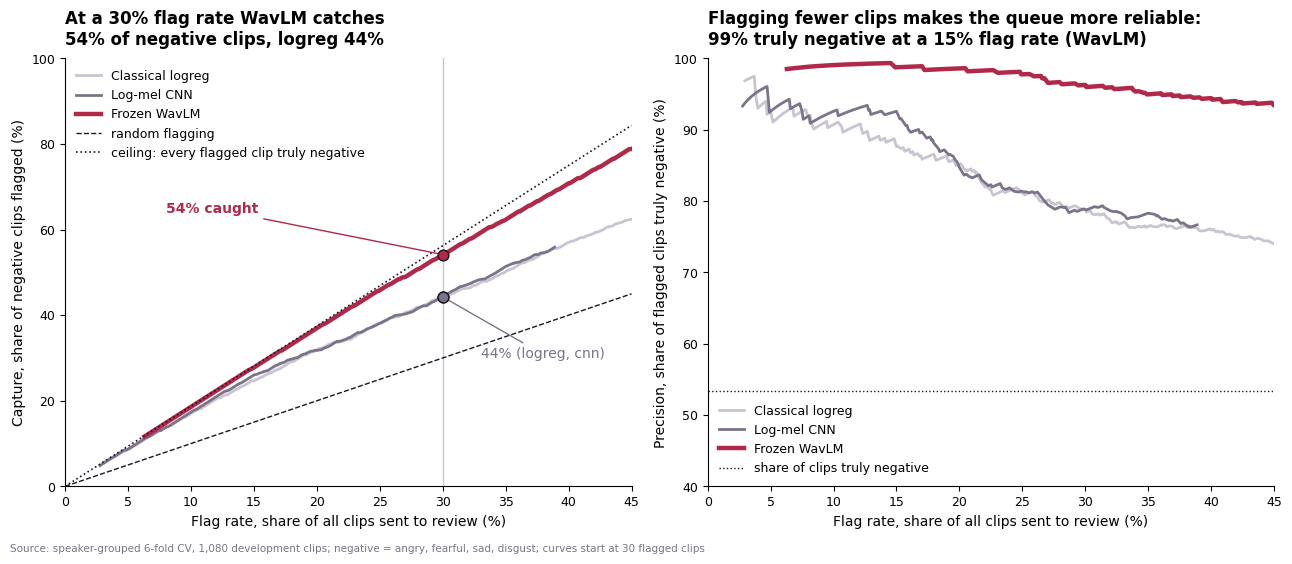

In [5]:
# F14: capture (left) and precision (right) against the flag rate.
# Curves start once 30 clips are flagged; below that a few clips
# swing the percentages.
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.6))
for m in RUNGS:
    sw = SWEEP[m][SWEEP[m]["n_flagged"] >= 30]
    lw = 3.2 if m == "wavlm" else 2
    a1.plot(100 * sw["flag_rate"], 100 * sw["capture"],
            color=RUNG_COLOR[m], lw=lw, label=RUNG_LABEL[m])
    a2.plot(100 * sw["flag_rate"], 100 * sw["precision"],
            color=RUNG_COLOR[m], lw=lw, label=RUNG_LABEL[m])
# Two reference lines: random flagging catches as many negatives as
# the flag rate; a perfect queue catches flag rate / base rate.
xs = np.array([0, 45])
a1.plot(xs, xs, color=U.INK, ls="--", lw=1, label="random flagging")
a1.plot(xs, xs / base, color=U.INK, ls=":", lw=1.2,
        label="ceiling: every flagged clip truly negative")
a2.axhline(100 * base, color=U.INK, ls=":", lw=1,
           label="share of clips truly negative")
for m in RUNGS:
    a1.scatter([30], [100 * cap.loc[m, 0.30]], s=60, zorder=5,
               color=RUNG_COLOR[m], edgecolor=U.INK)
a1.annotate(
    f"{100 * cap.loc['wavlm', 0.30]:.0f}% caught",
    xy=(30, 100 * cap.loc["wavlm", 0.30]), xytext=(8, 64),
    fontsize=10, color=U.ACCENT, fontweight="600",
    arrowprops={"arrowstyle": "-", "color": U.ACCENT})
a1.annotate(
    f"{100 * cap.loc['logreg', 0.30]:.0f}% (logreg, cnn)",
    xy=(30, 100 * cap.loc["logreg", 0.30]), xytext=(33, 30),
    fontsize=10, color=U.GREY,
    arrowprops={"arrowstyle": "-", "color": U.GREY})
a1.axvline(30, color=U.MUTED, lw=1, zorder=0)
a1.set_xlim(0, 45)
a1.set_ylim(0, 100)
a2.set_xlim(0, 45)
a2.set_ylim(40, 100)
U.finish_axes(
    a1,
    f"At a 30% flag rate WavLM catches\n"
    f"{100 * cap.loc['wavlm', 0.30]:.0f}% of negative clips, "
    f"logreg {100 * cap.loc['logreg', 0.30]:.0f}%",
    "Flag rate, share of all clips sent to review (%)",
    "Capture, share of negative clips flagged (%)",
    source="", legend=True)
U.finish_axes(
    a2,
    f"Flagging fewer clips makes the queue more reliable:\n"
    f"{100 * prec.loc['wavlm', 0.15]:.0f}% truly negative at a 15% "
    f"flag rate (WavLM)",
    "Flag rate, share of all clips sent to review (%)",
    "Precision, share of flagged clips truly negative (%)",
    source=("Source: speaker-grouped 6-fold CV, 1,080 development "
            "clips; negative = angry, fearful, sad, disgust; curves "
            "start at 30 flagged clips"),
    legend=True)
U.save_figure(fig, "F14_flag_rate.png", out_dir=FIGS)
plt.show()

In [6]:
# Review-queue sample: twelve clips spread evenly down the queue that
# the selected rung flags at a 30% flag rate, most confident first (the
# top of the queue is all confidence 1.0, so it shows nothing alone).
thr = at_flag_rate(SWEEP["wavlm"], 0.30)["threshold"]
df = PRED["wavlm"]
flag = df["pred_emotion"].isin(NEGATIVE) & (df["pred_confidence"] >= thr)
full = (df[flag].sort_values("pred_confidence", ascending=False,
                             kind="stable")
        .reset_index(drop=True))
full.index = full.index + 1
pick = np.linspace(1, len(full), 12).round().astype(int)
queue = full.loc[pick, ["filepath", "true_emotion", "pred_emotion",
                        "pred_confidence"]].copy()
queue.index.name = "queue_position"
queue["truly_negative"] = queue["true_emotion"].isin(NEGATIVE)
queue.to_csv(TABLES / "review_queue_sample.csv")
# The operating point is fixed here, on development speakers only.
# `08_Final_test` reads it back; it is never re-tuned on held-out clips.
op = {
    "rung": "wavlm", "flag_rate": 0.30, "threshold": round(thr, 3),
    "negative_emotions": NEGATIVE,
    "dev_capture": round(float(cap.loc["wavlm", 0.30]), 4),
    "dev_precision": round(float(prec.loc["wavlm", 0.30]), 4),
    "source": "speaker-grouped 6-fold CV, 1,080 development clips",
}
(TABLES / "flag_operating_point.json").write_text(
    json.dumps(op, indent=2))
print("fixed operating point:", op)
n_neg = int(full["true_emotion"].isin(NEGATIVE).sum())
print(f"wavlm threshold for a 30% flag rate: {thr:.3f}; "
      f"{len(full)} clips flagged; sample of 12 from the queue")
display(queue[["true_emotion", "pred_emotion", "pred_confidence",
               "truly_negative"]])
print(f"truly negative in this sample: "
      f"{int(queue['truly_negative'].sum())} of 12; "
      f"in the whole queue: {n_neg} of {len(full)}")

fixed operating point: {'rung': 'wavlm', 'flag_rate': 0.3, 'threshold': 0.827, 'negative_emotions': ['angry', 'fearful', 'sad', 'disgust'], 'dev_capture': 0.5417, 'dev_precision': 0.963, 'source': 'speaker-grouped 6-fold CV, 1,080 development clips'}
wavlm threshold for a 30% flag rate: 0.827; 324 clips flagged; sample of 12 from the queue


,true_emotion,pred_emotion,pred_confidence,truly_negative
queue_position,,,,
1,disgust,disgust,1.0000,True
30,fearful,fearful,0.9999,True
60,disgust,disgust,0.9993,True
89,disgust,disgust,0.9978,True
118,angry,angry,0.9944,True
148,angry,angry,0.9890,True
177,fearful,fearful,0.9767,True
207,angry,angry,0.9611,True
236,fearful,fearful,0.9419,True


truly negative in this sample: 12 of 12; in the whole queue: 312 of 324


**Verdict: supported. [EVIDENCE]** Precision at a 15% flag rate against a 30% flag rate is 87.7% and 78.7% for logistic regression, 92.6% and 78.8% for the CNN, and 98.8% and 96.3% for WavLM, all above the 53.3% share of clips that are truly negative. In WavLM's queue at a 30% flag rate, 312 of the 324 flagged clips are truly negative.

**So we** present the flag rate as a dial that trades reviewing effort for reliability, and note that WavLM keeps its queue above 96% reliable even at 30%.

---
## Summary

In [7]:
summary = pd.DataFrame(SUMMARY).set_index("H")
with pd.option_context("display.max_colwidth", 88):
    display(summary)
summary.to_csv(TABLES / "summary_07.csv")

,hypothesis,verdict,evidence,so we
H,,,,
H35,"At the same reviewing effort, a higher rung catches more of the negative clips",partly supported,"capture at 30% flag rate: wavlm 54.2%, logreg 44.3%, cnn 44.3%",quote flag results at equal flag rate and state where the gain is small
H36,A stricter flag rule flags a more reliable set at every rung,supported,precision at 15% / 30% flag rate: logreg 87.7% / 78.7%; cnn 92.6% / 78.8%; wavlm 98....,present the flag rate as a dial that trades effort for reliability


**Hands on:** `outputs/tables/flag_rate_sweep_by_rung.csv` and
`capture_at_equal_flag_rate.csv` hold the sweep for the report;
`08_Final_test` reuses the same rule on the held-out speakers, with the
threshold fixed here before any held-out clip is scored.